# SoluAI: predicting water solubility with machine learning

This notebook tells the story of the project step by step:

1. **The data**: what molecules we have and how we cleaned them
2. **The chemist's formula**: Delaney's ESOL equation (2004)
3. **Turning molecules into numbers**: descriptors and fingerprints
4. **Two kinds of exam**: random split vs scaffold split
5. **The results**: every model, honestly compared
6. **Looking inside the model**: SHAP, and does it think like a chemist?
7. **How sure is it?** Confidence ranges and "outside experience"
8. **Where it fails**: real failure cases

> The full experiment (all models, hyper-parameter search, final model) is run by one command:
> `python -m soluai.train --config config.yaml`. This notebook **reads its saved results**
> and re-runs only small, fast pieces so you can see how they work.

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from soluai.data import load_clean
from soluai.features import Featurizer, DESCRIPTOR_NAMES
from soluai.baselines import delaney_predict
from soluai.evaluate import metrics

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
ACCENT, GREY = "#0e7490", "#94a3b8"
M = json.loads((ROOT / "results/metrics.json").read_text())
REP = json.loads((ROOT / "results/report.json").read_text())

## 1. The data

We use two public datasets:

* **AqSolDB** (Sorkun et al., 2019): 9,982 compounds merged from 9 sources. This is our main dataset.
* **ESOL** (Delaney, 2004): 1,128 compounds, the classic benchmark.

Cleaning rules (see `src/soluai/data.py`): remove unreadable SMILES, **salts and mixtures**, and
**inorganic** compounds; neutralise charges; write every molecule in one standard way (canonical SMILES);
average duplicates that agree, and drop duplicates that disagree by more than 0.5 log units.

In [2]:
pd.DataFrame(M["cleaning"]).fillna(0).astype(int)

,aqsoldb,esol
input_rows,9982,1128
salt_or_mixture,1098,0
ok,8761,1128
no_carbon,91,0
non_organic_element,30,0
invalid_smiles,2,0
duplicate_groups,6,11
duplicates_conflicting_dropped,1,1
output_rows,8754,1116


About 11% of AqSolDB entries are salts or mixtures (for example `[Na+].[Cl-]`, or a drug together with its counter-ion). We
**removed** them rather than stripping the ions, because the solubility of a salt is not the solubility of
its organic part. That leaves **8,754** clean organic molecules.

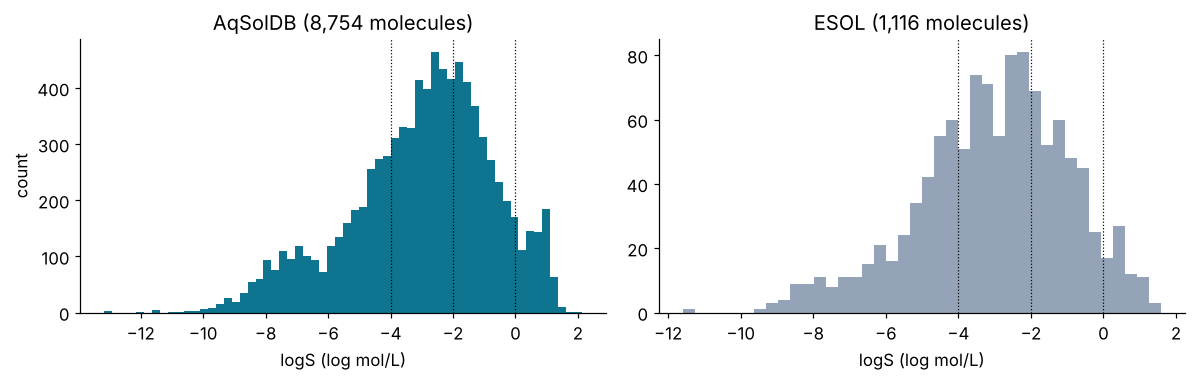

In [3]:
aq, esol = load_clean("aqsoldb"), load_clean("esol")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(aq.logS, bins=60, color=ACCENT); ax[0].set(title="AqSolDB (8,754 molecules)", xlabel="logS (log mol/L)", ylabel="count")
ax[1].hist(esol.logS, bins=40, color=GREY); ax[1].set(title="ESOL (1,116 molecules)", xlabel="logS (log mol/L)")
for a in ax:
    for x in (-4, -2, 0): a.axvline(x, ls=":", c="k", lw=.8)
plt.tight_layout()

AqSolDB covers a much wider range (and many more "insoluble" molecules) than ESOL. That makes it harder,
and also more realistic.

Let's look at the two most famous trends: **logS vs logP** (oiliness) and **logS vs molecular weight** (size).

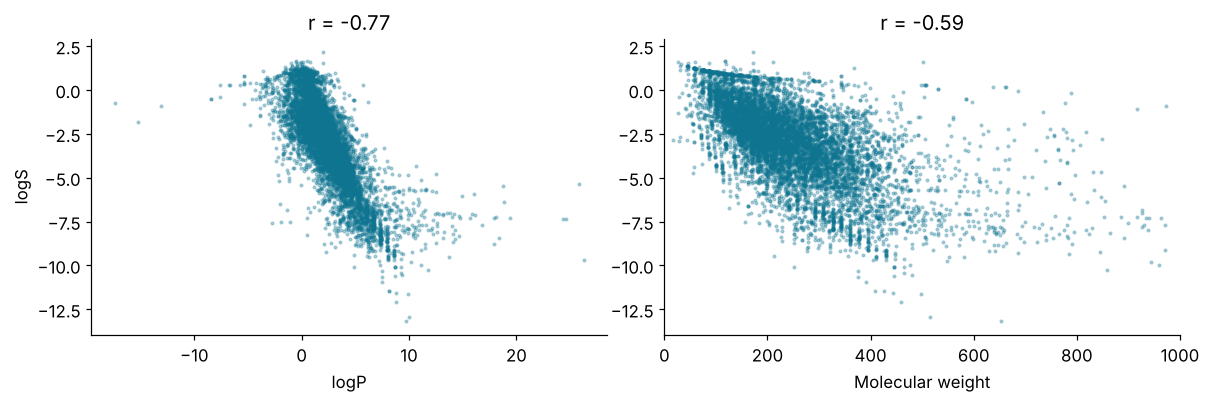

In [4]:
F = Featurizer("desc")
X_aq = pd.DataFrame(F.transform(aq.smiles), columns=DESCRIPTOR_NAMES)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].scatter(X_aq.MolLogP, aq.logS, s=3, alpha=.3, c=ACCENT); ax[0].set(xlabel="logP", ylabel="logS", title=f"r = {np.corrcoef(X_aq.MolLogP, aq.logS)[0,1]:.2f}")
ax[1].scatter(X_aq.MolWt, aq.logS, s=3, alpha=.3, c=ACCENT); ax[1].set(xlabel="Molecular weight", title=f"r = {np.corrcoef(X_aq.MolWt, aq.logS)[0,1]:.2f}"); ax[1].set_xlim(0, 1000)
plt.tight_layout()

## 2. The chemist's formula: Delaney's ESOL equation

In 2004 John Delaney fitted a straight line using four variables a chemist knows matter:

$$\log S = 0.16 - 0.63\,\text{clogP} - 0.0062\,\text{MW} + 0.066\,\text{RB} - 0.74\,\text{AP}$$

(RB = rotatable bonds, AP = aromatic proportion.) We use RDKit's Crippen logP in place of the commercial clogP program,
so our numbers differ a little from his paper.

In [5]:
for name, df in [("ESOL", esol), ("AqSolDB", aq)]:
    print(f"{name:8s} Delaney equation on ALL molecules:", metrics(df.logS, delaney_predict(df.smiles)))

ESOL     Delaney equation on ALL molecules: {'rmse': 1.101, 'mae': 0.845, 'r2': 0.723}


AqSolDB  Delaney equation on ALL molecules: {'rmse': 1.337, 'mae': 0.983, 'r2': 0.664}


The formula works better on ESOL (the dataset it was designed on) than on the larger and more varied AqSolDB.
This is our **"human" baseline** to beat.

## 3. Turning molecules into numbers

A model can't read a molecule; it needs numbers.

* **14 descriptors**: logP, molecular weight, polar surface area (TPSA), H-bond donors/acceptors, rotatable bonds,
  aromatic proportion, number of rings, and so on.
* **Morgan fingerprint**: 1,024 yes/no bits. Each bit means "this small fragment (an atom plus its neighbours up to 2 bonds away) is present".

In [6]:
from rdkit import Chem
f = Featurizer("desc+fp")
mol = Chem.MolFromSmiles("CC(=O)Oc1ccccc1C(=O)O")  # aspirin
x = f.transform_mol(mol)
print("aspirin descriptors:")
print(pd.Series(x[:14], index=DESCRIPTOR_NAMES).round(2).to_string())
print(f"\nfingerprint: {int(x[14:].sum())} of 1024 bits are 'on'")

aspirin descriptors:
MolLogP                  1.31
MolWt                  180.16
TPSA                    63.60
NumHDonors               1.00
NumHAcceptors            3.00
NumRotatableBonds        2.00
AromaticProportion       0.46
FractionCSP3             0.11
RingCount                1.00
NumAromaticRings         1.00
HeavyAtomCount          13.00
NumHeteroatoms           4.00
MolMR                   44.71
NumValenceElectrons     68.00

fingerprint: 24 of 1024 bits are 'on'


## 4. Two kinds of exam: random vs scaffold split

* **Random split**: shuffle all molecules and hide 20% as a test set. Test molecules often have a close "cousin"
  in the training set (for example, 1-hexanol in training and 1-heptanol in test). This is the easy exam.
* **Scaffold split**: group molecules by their **ring skeleton** (Bemis–Murcko scaffold) and hide *whole groups*.
  The test molecules have skeletons the model has never seen. This is the hard exam, and closer to how a chemist would use the model on a new compound.

In both cases:
* model settings are chosen with **5-fold cross-validation on the training part only**;
* the test set is used **exactly once**, at the very end.

In [7]:
from soluai.splits import scaffold
for s in ["c1ccccc1O", "CC(=O)Oc1ccccc1C(=O)O", "CCO", "Cn1cnc2c1c(=O)n(C)c(=O)n2C"]:
    print(f"{s:30s} -> scaffold: {scaffold(s) or '(none: no rings)'}")

c1ccccc1O                      -> scaffold: c1ccccc1
CC(=O)Oc1ccccc1C(=O)O          -> scaffold: c1ccccc1
CCO                            -> scaffold: (none: no rings)
Cn1cnc2c1c(=O)n(C)c(=O)n2C     -> scaffold: O=c1[nH]c(=O)c2[nH]cnc2[nH]1


## 5. The results

All numbers below are on the **held-out test sets**. RMSE and MAE are in log units (lower is better);
R² is the share of the variation explained (higher is better).

In [8]:
res = pd.DataFrame(M["results"])
table = res.pivot_table(index=["model", "features"], columns=["dataset", "split"], values="test_rmse")
table = table[[("aqsoldb", "random"), ("aqsoldb", "scaffold"), ("esol", "random"), ("esol", "scaffold")]]
table.round(3)

dataset                        aqsoldb            esol         
split                           random scaffold random scaffold
model              features                                    
Delaney (original) 4 ESOL vars   1.353    1.440  1.070    1.239
Delaney (refit)    4 ESOL vars   1.336    1.412  0.920    1.228
LightGBM           desc          0.935    1.075  0.643    0.935
                   desc+fp       0.835    1.012  0.605    0.833
                   fp            1.146    1.413  1.083    1.490
Linear regression  desc          1.311    1.409  0.888    1.209
Random forest      desc          0.942    1.121  0.665    0.880
                   desc+fp       0.877    1.070  0.616    0.809
                   fp            1.252    1.555  1.194    1.510

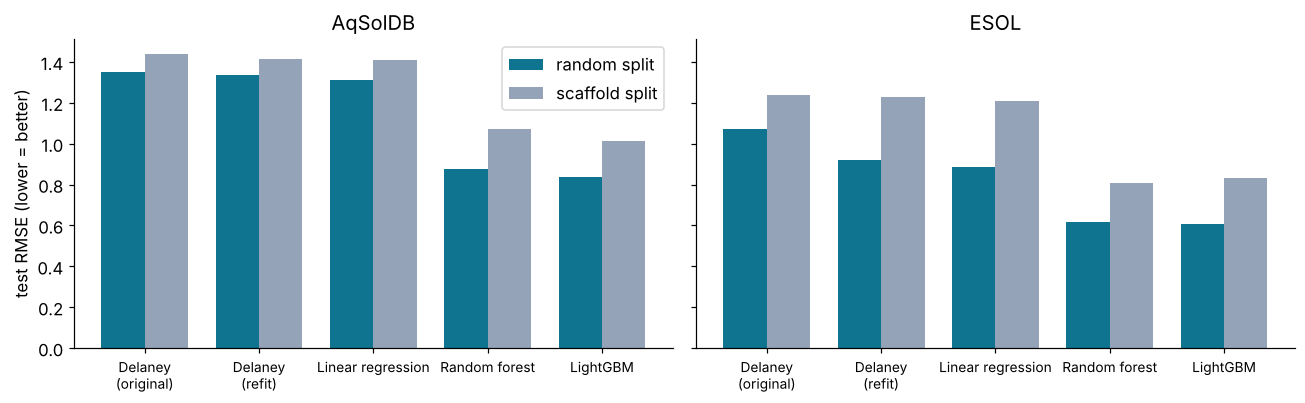

In [9]:
best = res.loc[res.groupby(["dataset", "split", "model"]).cv_rmse.idxmin()]
order = ["Delaney (original)", "Delaney (refit)", "Linear regression", "Random forest", "LightGBM"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, ds in zip(axes, ["aqsoldb", "esol"]):
    for k, (split, col) in enumerate([("random", ACCENT), ("scaffold", GREY)]):
        sub = best[(best.dataset == ds) & (best.split == split)].set_index("model").loc[order]
        ax.bar(np.arange(5) + (k - .5) * .38, sub.test_rmse, .38, color=col, label=f"{split} split")
    ax.set_xticks(range(5), [o.replace(" (", "\n(") for o in order], fontsize=9); ax.set_title(ds.upper() if ds == "esol" else "AqSolDB")
axes[0].set_ylabel("test RMSE (lower = better)"); axes[0].legend()
plt.tight_layout()

What we see:

* Machine learning (random forest, LightGBM) clearly beats Delaney's hand-made formula and plain linear regression on both datasets.
* Scores on the **scaffold split are worse** than on the random split. Predicting brand-new skeletons is harder, and the
  random split slightly *overestimates* how good the model is on truly new chemistry.
* **Fingerprints alone** are worse than descriptors. Combining both is best or close to best: descriptors carry
  the big physical trends (logP, size), and fingerprints add specific groups.
* Random forest and LightGBM are very close. We deploy LightGBM because it is small, fast, and computes exact SHAP explanations
  with very little memory, which matters on a free web server.

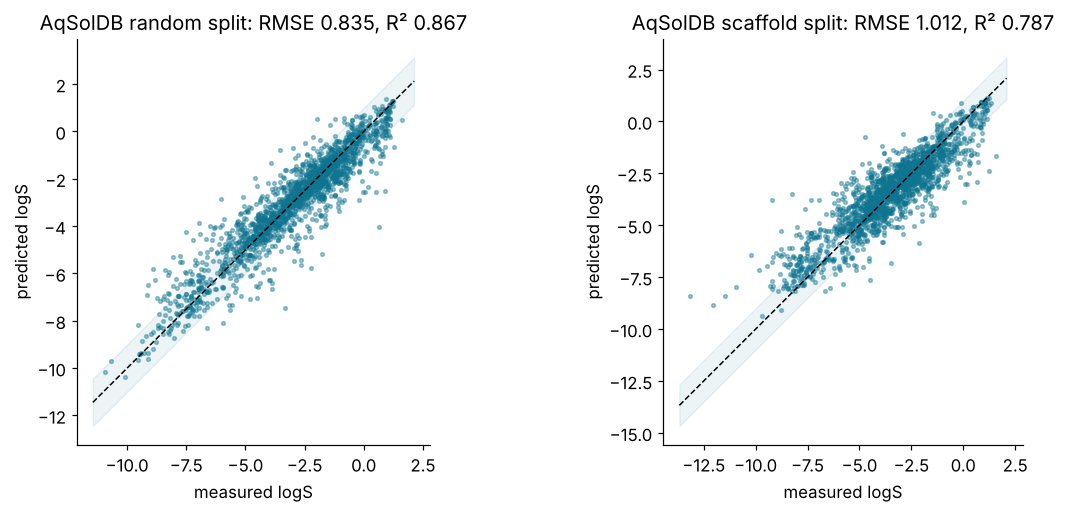

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, split in zip(axes, ["random", "scaffold"]):
    s = REP["splits"]["aqsoldb"][split]
    key = [k for k in s["predictions"] if k.startswith("LightGBM")][0]
    y, p = np.array(s["y_test"]), np.array(s["predictions"][key])
    ax.scatter(y, p, s=6, alpha=.4, c=ACCENT); lim = [y.min() - .5, y.max() + .5]
    ax.plot(lim, lim, "k--", lw=1); ax.fill_between(lim, [l - 1 for l in lim], [l + 1 for l in lim], color=ACCENT, alpha=.08)
    m = metrics(y, p); ax.set(xlabel="measured logS", ylabel="predicted logS", title=f"AqSolDB {split} split: RMSE {m['rmse']}, R² {m['r2']}")
    ax.set_aspect("equal")
plt.tight_layout()

### Can we test the AqSolDB model on ESOL?

That would be a nice extra check, but first we must see whether the two datasets share molecules:

In [11]:
M["esol_overlap"]

{'n_esol': 1116, 'n_in_aqsoldb': 1115, 'n_not_in_aqsoldb': 1}

**Almost every ESOL molecule is already in AqSolDB.** AqSolDB was built by merging older datasets, including Delaney's. Testing the
AqSolDB model on ESOL would mean testing it on molecules it had already learned from, so we **do not** report such a score.
ESOL is used as a separate, smaller benchmark with its own random and scaffold splits (the tables above).

## 6. Looking inside the model

**SHAP** values say how much each feature pushed one prediction up or down compared with the average molecule.
They always add up exactly: *prediction = average + sum of SHAP values*.

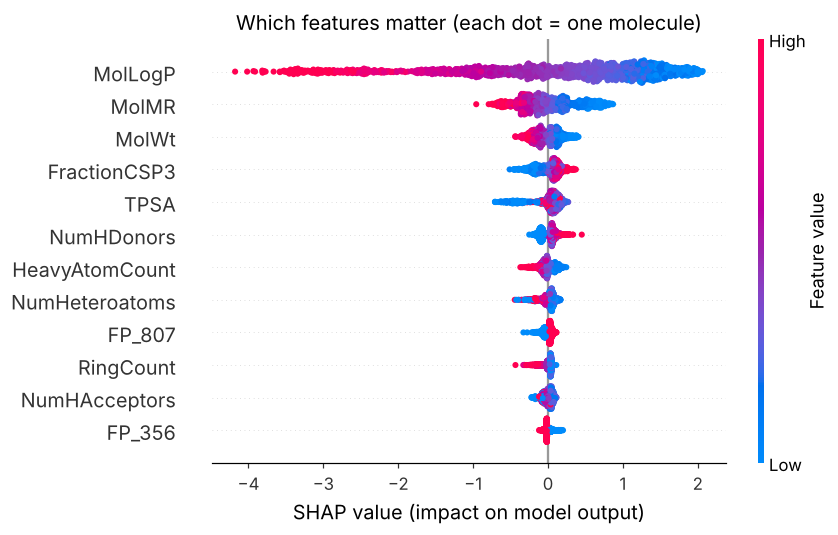

In [12]:
import shap, joblib
from soluai.predict import Predictor
P = Predictor()
Xf = P.featurizer.transform(aq.smiles.sample(1500, random_state=0))
sv = shap.TreeExplainer(P.model).shap_values(Xf)
names = [n if not n.startswith("FP_") else n for n in P.feature_names]
shap.summary_plot(sv, Xf, feature_names=names, max_display=12, show=False, plot_size=(8, 5))
plt.title("Which features matter (each dot = one molecule)"); plt.tight_layout()

In [13]:
print("Correlation between feature value and its SHAP push (negative = lowers solubility as it grows):")
pd.Series(REP["shap_trend_correlation"]).round(2)

Correlation between feature value and its SHAP push (negative = lowers solubility as it grows):


MolLogP              -0.92
MolWt                -0.83
TPSA                  0.33
NumHDonors            0.80
NumHAcceptors        -0.25
AromaticProportion   -0.61
dtype: float64

**Does the model think like a chemist?** Mostly, yes:

| Chemistry says… | Model learned… |
|---|---|
| Oily molecules (high logP) dissolve less | logP is the #1 feature and pushes solubility **down** |
| Polar surface / H-bonding helps | TPSA and H-bond donors push solubility **up** |
| Bigger molecules dissolve less | molecular weight pushes **down** |
| Flat aromatic crystals dissolve less | aromatic proportion pushes **down** |

The model was never told any of these rules; it found them in the data. Its main blind spot is the **crystal**:
it only sees the 2D structure, so it cannot know the melting point (see the failure cases below).

glucose: logS = 0.48  (Highly soluble),  90% range [-1.01, 1.97]
   - The five –OH groups increase solubility because they form hydrogen bonds with water.
   - The ether oxygen (–O–) increases solubility because its oxygen accepts hydrogen bonds from water.
   - Its logP is -3.2: it prefers water to oil (about 2 thousand to 1), so it is water-loving (hydrophilic).


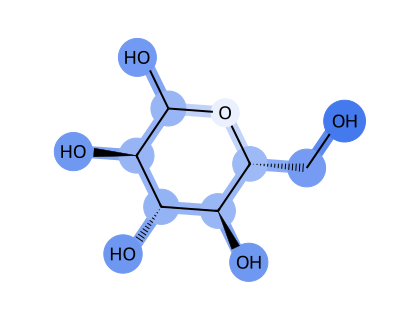

1-octanol: logS = -2.29  (Slightly soluble),  90% range [-3.78, -0.8]
   - The long carbon chain decreases solubility because it is non-polar - water cannot hydrogen-bond to it.
   - The –OH group increases solubility because it forms hydrogen bonds with water.
   - Its logP is 2.3: it prefers oil to water about 220 to 1, so it is quite oily (hydrophobic).


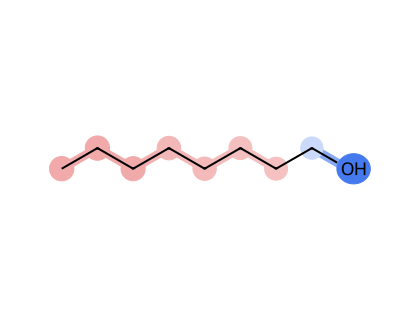

aspirin: logS = -1.62  (Soluble),  90% range [-3.11, -0.14]
   - The benzene ring decreases solubility because it is non-polar and flat, so it avoids water and packs tightly in crystals.
   - The –COOH (carboxylic acid) group increases solubility because it forms strong hydrogen bonds with water.
   - Its logP is 1.3: it prefers oil to water about 20 to 1, so it is mildly oily.


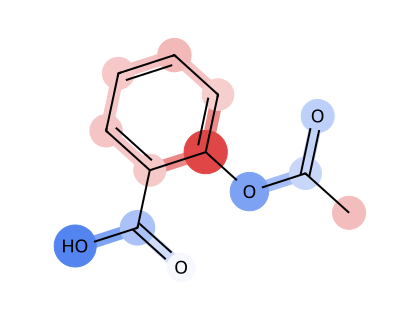

In [14]:
from IPython.display import SVG, display
from soluai.explain import analyze
for name, smi in [("glucose", "OC[C@H]1OC(O)[C@H](O)[C@@H](O)[C@@H]1O"), ("1-octanol", "CCCCCCCCO"), ("aspirin", "CC(=O)Oc1ccccc1C(=O)O")]:
    r = analyze(P, Chem.MolFromSmiles(smi))
    print(f"{name}: logS = {r['logS']}  ({r['category']}),  90% range {r['interval']}")
    for s in r["explanation"]: print("   -", s)
    display(SVG(r["svg_explained"]))

Blue atoms raise the predicted solubility; red atoms lower it. Each feature's SHAP push is shared among the atoms
responsible for it (a fragment's atoms, each atom's logP contribution, the O/N atoms that make hydrogen bonds, and so on).

## 7. How sure is the model?

* **Applicability domain:** for each molecule we find its *most similar* training molecule (Tanimoto similarity of fingerprints).
  Below 0.30 we say the molecule is **"outside the model's experience"**.
* **90% range (conformal prediction):** we look at the model's errors on molecules it did not see (cross-validation),
  and make the range wide enough to cover 90% of them. It is computed separately for familiar and unfamiliar molecules.

In [15]:
rows = []
for ds in ["aqsoldb", "esol"]:
    for split in ["random", "scaffold"]:
        u = REP["splits"][ds][split]["uncertainty"]
        rows.append({"dataset": ds, "split": split, "± familiar": u["half_width_in"], "± unfamiliar": u["half_width_out"],
                     "coverage (target 90%)": u["coverage_all"], "share unfamiliar": u["share_out_of_domain"],
                     "RMSE familiar": u["rmse_in"], "RMSE unfamiliar": u["rmse_out"]})
pd.DataFrame(rows)

,dataset,split,± familiar,± unfamiliar,coverage (target 90%),share unfamiliar,RMSE familiar,RMSE unfamiliar
0,aqsoldb,random,1.301,1.931,0.886,0.023,0.831,0.984
1,aqsoldb,scaffold,1.456,1.556,0.866,0.080,1.004,1.101
2,esol,random,0.930,1.375,0.888,0.080,0.610,0.535
3,esol,scaffold,1.304,1.283,0.890,0.233,0.698,1.171


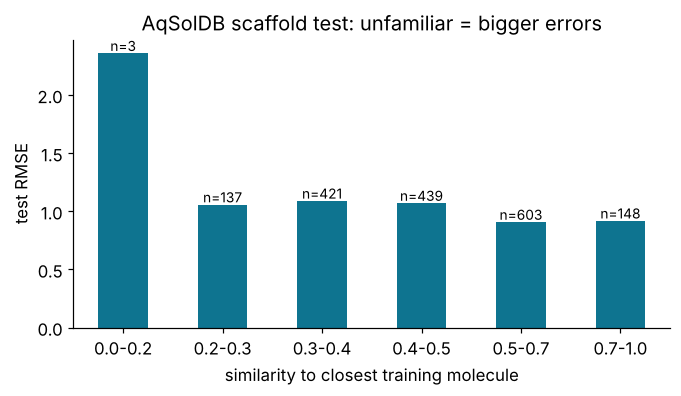

In [16]:
b = pd.DataFrame(REP["splits"]["aqsoldb"]["scaffold"]["uncertainty"]["error_by_similarity"])
ax = b.plot.bar(x="range", y="rmse", color=ACCENT, legend=False, figsize=(7, 3.4), rot=0)
for i, n in enumerate(b.n): ax.text(i, b.rmse[i] + .02, f"n={n}", ha="center", fontsize=9)
ax.set(xlabel="similarity to closest training molecule", ylabel="test RMSE", title="AqSolDB scaffold test: unfamiliar = bigger errors");

## 8. Where the model fails

The biggest errors on the AqSolDB scaffold test set:

In [17]:
s = REP["splits"]["aqsoldb"]["scaffold"]
key = [k for k in s["predictions"] if k.startswith("LightGBM")][0]
te = aq.iloc[s["test_idx"]].copy()
te["predicted"] = s["predictions"][key]; te["error"] = te.predicted - te.logS; te["similarity"] = s["similarity_test"]
worst = te.reindex(te.error.abs().sort_values(ascending=False).index).head(12)
worst[["name", "smiles", "logS", "predicted", "error", "similarity", "group"]].round(2)

,name,smiles,logS,predicted,error,similarity,group
1947,"2-[(1-amino-4-hydroxy-9,10-dioxo-9,10-dihydroa...",CCOC(=O)OCCOc1cc(O)c2c(c1N)C(=O)c1ccccc1C2=O,-9.22,-3.76,5.46,0.74,G1
6316,"4,11-diamino-2-[3-(2-methoxyethoxy)propyl]-1H-...",COCCOCCCn1c(=O)c2c(N)c3c(=O)c4ccccc4c(=O)c3c(N...,-8.27,-3.49,4.78,0.35,G1
6652,dechlorane plus,ClC1=C(Cl)C2(Cl)C3CCC4C(CCC3C1(Cl)C2(Cl)Cl)C1(...,-13.17,-8.42,4.75,0.50,G1
2711,Tetra(10B)boron carbide,B12B3B4B1C234,-4.74,-0.74,4.01,0.10,G2
1706,"1,4-bis({3-[2-(2-hydroxyethoxy)ethoxy]propyl}a...",O=C1c2ccccc2C(=O)c2c(NCCCOCCOCCO)ccc(NCCCOCCOC...,0.06,-3.86,-3.91,0.37,G3
122,"1,1'-[iminobis(ethyleneiminoethylene)]bis[3-(o...",CCCCCCCCCCCCCCCCCCC1CC(=O)N(CCNCCNCCNCCN2C(=O)...,-10.23,-6.46,3.78,0.35,G1
767,"N,N-diethyl-1-phenothiazin-10-ylpropan-2-amine",CCN(CC)C(C)CN1c2ccccc2Sc2ccccc21,-2.15,-5.87,-3.72,0.38,G1
2663,"1,8-anthraquinonedisulfonic acid",O=C1c2cccc(S(=O)(=O)O)c2C(=O)c2c1cccc2S(=O)(=O)O,1.26,-2.40,-3.66,0.47,G1
2433,"hexamethyl-1,3,5,2,4,6-trioxatrisilinane",C[Si]1(C)O[Si](C)(C)O[Si](C)(C)O1,0.65,-2.94,-3.59,1.00,G2
7269,"4,11-diamino-2-(3-methoxypropyl)-1H,2H,3H,5H,1...",COCCCn1c(=O)c2c(N)c3c(=O)c4ccccc4c(=O)c3c(N)c2...,-7.32,-3.80,3.53,0.33,G3


Typical patterns in the failures (see `docs/model_card.md` for a discussion):

* **High-melting, flat, symmetric molecules** (dyes, polycyclic aromatics, some steroids): predicted *too soluble*, because the model
  cannot see how tightly they pack in a crystal.
* **Very large or unusual molecules** (organosilicon, long fluorinated chains, big pigments): few similar training examples.
* **Questionable data**: AqSolDB groups data by reliability (G1 = a single source … G5 = several sources that agree). Some of the
  largest "errors" come from single-source (G1) values that may themselves be wrong.

## Summary

* A tuned tree model on descriptors + fingerprints predicts logS with a typical error below 1 log unit on a random split,
  and somewhat worse on new skeletons. Both clearly beat Delaney's 2004 formula.
* The model rediscovered the main chemistry rules: polarity/logP, hydrogen bonding, size and aromaticity.
* It knows when it is unsure (similarity-based warning + 90% range), and its main blind spot, crystal packing, is a real chemical effect it cannot see from a 2D drawing.